***TP2 : Prétraitement avancé***

****Partie 1 — Explorer et vérifier les données****

**1 telechargement de dataset**

In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
df = pd.read_csv("/home/hassan/Desktop/master/aprentissage/TPs/tp2/transactions_TP2 - transactions_TP2.csv")

df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


*nombre des lignes et des colonnes*

In [113]:
df.shape

(3045, 12)

**types de variables.**

In [114]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

***2 le nombre et le pourcentage de valeurs manquantes de chaque colonne.***

In [115]:

nb_manquante = df.isnull().sum()
pct_manquante = (df.isnull().sum() / len(df)) * 100
table = pd.DataFrame({
    "Nombre de valeurs manquantes": nb_manquante,
    "Pourcentage (%)": pct_manquante})
table = table.sort_values(
    by="Pourcentage (%)",
    ascending=False)
display(table.round(2))

,Nombre de valeurs manquantes,Pourcentage (%)
canal,159,5.22
anciennete_mois,137,4.50
appareil,122,4.01
montant_dh,110,3.61
region,103,3.38
nb_ops_24h,53,1.74
id_operation,0,0.00
id_client,0,0.00
heure,0,0.00
international,0,0.00


**3. Détection et suppression des doublons**

In [116]:
nb_doublons=df["id_operation"].duplicated().sum()

In [117]:
nb_doublons

np.int64(45)

*supprission des doublons*

In [118]:
df = df.drop_duplicates(subset="id_operation", keep="first")
print(len(df))


3000


**4. Analyse des valeurs extrêmes du montant**

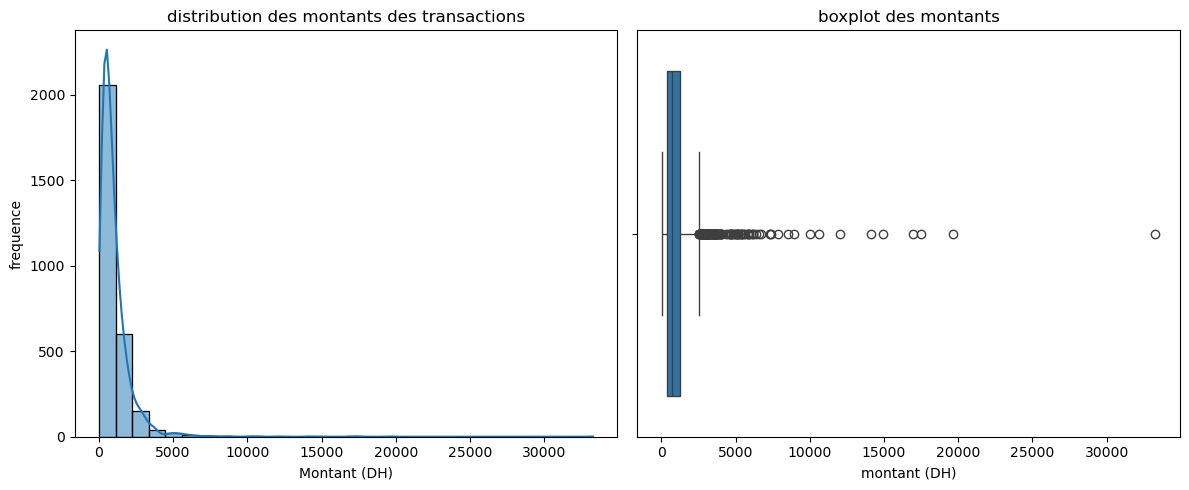

In [119]:

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['montant_dh'], bins=30, kde=True)
plt.title("distribution des montants des transactions")
plt.xlabel("Montant (DH)")
plt.ylabel("frequence")

# boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df['montant_dh'])
plt.title("boxplot des montants")
plt.xlabel("montant (DH)")

plt.tight_layout()
plt.show()

*ANALISE :
Nous avons utilisé un histogramme et un boxplot pour visualiser la distribution des montants des transactions (montant_dh).

L histogramme permet de voir la répartition des montants, tandis que le boxplot permet de détecter les valeurs extrêmes. On remarque que certains montants sont éloignés de la majorité des transactions.

Il ne faut pas forcément supprimer ces valeurs extrêmes, car elles peuvent correspondre à des transactions bancaires réelles, même si leurs montants sont élevés. Dans le cas de la détection de fraude, ces valeurs peuvent être importantes pour identifier des opérations suspectes.

Donc, il est préférable d analyser ces montants avant de décider de les supprimer ou de les conserver.*

***5. Analyse de la répartition des classes***

In [120]:

effectifs = df["fraude"].value_counts().sort_index()
proportions = df["fraude"].value_counts(normalize=True).sort_index() * 100
print("Nombre d'opérations par classe :")
print(effectifs)



Nombre d'opérations par classe :
fraude
0    2742
1     258
Name: count, dtype: int64



Proportion de chaque classe  en (%) :
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


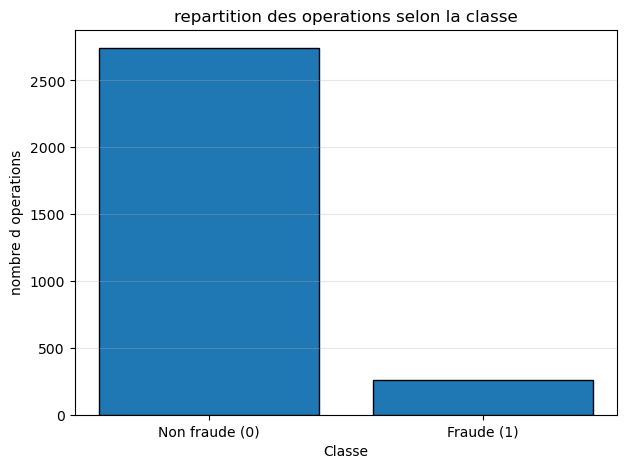

In [121]:
print("\nProportion de chaque classe  en (%) :")
print(proportions.round(2))
plt.figure(figsize=(7, 5))
plt.bar(
    ["Non fraude (0)", "Fraude (1)"],
    [effectifs.get(0, 0), effectifs.get(1, 0)],
    edgecolor="black")
plt.title("repartition des operations selon la classe")
plt.xlabel("Classe")
plt.ylabel("nombre d operations")
plt.grid(axis="y", alpha=0.3)
plt.show()

*justification :
L analyse de la répartition des classes permet de vérifier si le nombre d opérations normales (`fraude = 0`) est proche du nombre d opérations frauduleuses (`fraude = 1`).

Cette vérification est importante, car un déséquilibre entre les deux classes peut influencer l apprentissage d un modèle de Machine Learning. En effet, le modèle risque de favoriser la classe majoritaire et de mal détecter les opérations frauduleuses, qui représentent généralement la classe minoritaire.

Il est donc nécessaire d étudier cet équilibre avant de préparer les données afin de choisir une méthode adaptée, comme le suréchantillonnage (Oversampling), le sous-échantillonnage (Undersampling) ou SMOTE.*

**6. Identification des colonnes à exclure**

In [122]:
# Identifier les colonnes à exclure
colonnes_exclues = ["id_operation", "id_client", "resultat_enquete"]

print("Colonnes à exclure des variables préparées :")
print(colonnes_exclues)

Colonnes à exclure des variables préparées :
['id_operation', 'id_client', 'resultat_enquete']


*Justification:*
Les colonnes id_operation et id_client sont des identifiants qui servent uniquement à reconnaître les opérations et les clients. Elles ne sont pas utiles pour l'apprentissage.

La colonne `resultat_enquete` doit également être exclue, car elle est connue uniquement après l'enquête bancaire. Son utilisation provoquerait une fuite de données (*Data Leakage*), puisque cette information n'est pas disponible au moment de la détection de la fraude.

-> ces trois colonnes doivent être exclues des variables explicatives pour éviter la fuite de données et garantir un apprentissage correct.*

***Partie 2 — Préparer les données sans fuite***

**7. Séparation des variables X et y**

In [123]:
y = df["fraude"]
X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# verification
display(X.head())
display(y.head())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)


,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
0,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non
1,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non
2,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non
3,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non
4,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non


0    0
1    0
2    0
3    0
4    0
Name: fraude, dtype: int64


***8. Division des données en deux groupes***

In [124]:
from sklearn.model_selection import train_test_split
X_ref, X_ver, y_ref, y_ver = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42)
print("rroportion dans le groupe de référence en (%) :")
print((y_ref.value_counts(normalize=True) * 100).round(2))

print("\nproportion dans le groupe de vérification  en (%) :")
print((y_ver.value_counts(normalize=True) * 100).round(2))

rroportion dans le groupe de référence en (%) :
fraude
0    91.42
1     8.58
Name: proportion, dtype: float64

proportion dans le groupe de vérification  en (%) :
fraude
0    91.33
1     8.67
Name: proportion, dtype: float64


**9. Liste des variables numériques et catégorielles**

In [125]:
#variable nummeriques 
variables_numeriques = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

#  variables catégorielles
variables_categorielles = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Variables numériques :")
print(variables_numeriques)

print("\nVariables catégorielles :")
print(variables_categorielles)

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']

Variables catégorielles :
['canal', 'appareil', 'region', 'international']


*interpretation*

*Les variables numériques sont : montant_dh , anciennete_mois, nb_ops_24h et heure .

Les variables catégorielles sont : canal, appareil, region et international.

Les variables comme canal et region représentent des catégories et non des quantités. Elles doivent donc être encodées avant d être utilisées dans un modèle de Machine Learning.*

**10. Pipeline pour les variables numériques**

In [126]:

num_cols = X_ref.select_dtypes(include=['int64', 'float64']).columns
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])
X_ref_num = num_pipeline.fit_transform(X_ref[num_cols])
X_ver_num = num_pipeline.transform(X_ver[num_cols])
medians = num_pipeline.named_steps['imputer'].statistics_
scales = num_pipeline.named_steps['scaler'].scale_
resultats = pd.DataFrame({
    'Variable': num_cols,
    'Médiane calculée': medians,
    'Échelle (écart-type)': scales})
print("--------resultat des pipline numeriques -----")
display(resultats.round(2))
dimensions = pd.DataFrame({
    'Groupe': ['Référence', 'Vérification'],
    'Nombre de lignes': [X_ref_num.shape[0], X_ver_num.shape[0]],
    'Nombre de colonnes': [X_ref_num.shape[1], X_ver_num.shape[1]]})
print("-----dimension apres transformation ------")
display(dimensions)

--------resultat des pipline numeriques -----


,Variable,Médiane calculée,Échelle (écart-type)
0,montant_dh,710.79,1327.63
1,anciennete_mois,87.00,49.49
2,nb_ops_24h,3.00,1.65
3,heure,11.00,7.00


-----dimension apres transformation ------


,Groupe,Nombre de lignes,Nombre de colonnes
0,Référence,2400,4
1,Vérification,600,4


**11 : Construction et application du pipeline de prétraitement des variables catégorielles**

In [127]:
from sklearn.preprocessing import OneHotEncoder
cat_cols = X_ref.select_dtypes(include=['object', 'category']).columns
print("Variables catégorielles :", list(cat_cols))
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])
X_ref_cat = cat_pipeline.fit_transform(X_ref[cat_cols])
X_ver_cat = cat_pipeline.transform(X_ver[cat_cols])
categories = cat_pipeline.named_steps['encoder'].get_feature_names_out(cat_cols)
print("\n -----------variable categorielles encodees-----------")
print("Catégories créées :", list(categories))
dimensions_cat = pd.DataFrame({
    'Groupe': ['Référence', 'Vérification'],
    'Nombre de lignes': [X_ref_cat.shape[0], X_ver_cat.shape[0]],
    'Nombre de colonnes': [X_ref_cat.shape[1], X_ver_cat.shape[1]]
})

print("\n----------- dimesion apres encodage---------")
display(dimensions_cat)

Variables catégorielles : ['canal', 'appareil', 'region', 'international']

 -----------variable categorielles encodees-----------
Catégories créées : ['canal_agence', 'canal_application', 'canal_site_web', 'canal_telephone', 'appareil_mobile', 'appareil_ordinateur', 'appareil_terminal', 'region_Autre', 'region_Casablanca-Settat', 'region_Draa-Tafilalet', 'region_Marrakech-Safi', 'region_Souss-Massa', 'international_non', 'international_oui']

----------- dimesion apres encodage---------


,Groupe,Nombre de lignes,Nombre de colonnes
0,Référence,2400,14
1,Vérification,600,14


**12 : Regroupement des pipelines avec ColumnTransformer**

In [128]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)])
X_ref_final = preprocessor.fit_transform(X_ref)
X_ver_final = preprocessor.transform(X_ver)
dimensions_final = pd.DataFrame({
    'Groupe': ['Référence', 'Vérification'],
    'Nombre de lignes': [
        X_ref_final.shape[0],
        X_ver_final.shape[0]
    ],
    'Nombre de colonnes': [
        X_ref_final.shape[1],
        X_ver_final.shape[1]
    ]})


print("========== DIMENSIONS APRÈS PRÉTRAITEMENT ==========")
display(dimensions_final)

========== DIMENSIONS APRÈS PRÉTRAITEMENT ==========


,Groupe,Nombre de lignes,Nombre de colonnes
0,Référence,2400,18
1,Vérification,600,18


**13 : Comparaison entre StandardScaler et RobustScaler**

In [129]:
from sklearn.preprocessing import RobustScaler

robust_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

X_ref_robust = robust_pipeline.fit_transform(X_ref[num_cols])
X_ver_robust = robust_pipeline.transform(X_ver[num_cols])

In [130]:

montants = X_ref['montant_dh'].dropna()
idx_ordinary = (montants - montants.median()).abs().idxmin()
idx_high = montants.idxmax()
col_position = list(num_cols).index('montant_dh')
resultats_comparaison = pd.DataFrame({
    'Type opération': ['Ordinaire', 'Montant très élevé'],
    'Montant initial (DH)': [
        X_ref.loc[idx_ordinary, 'montant_dh'],
        X_ref.loc[idx_high, 'montant_dh']
    ],
    'StandardScaler': [
        X_ref_num[X_ref.index.get_loc(idx_ordinary), col_position],
        X_ref_num[X_ref.index.get_loc(idx_high), col_position]
    ],
    'RobustScaler': [
        X_ref_robust[X_ref.index.get_loc(idx_ordinary), col_position],
        X_ref_robust[X_ref.index.get_loc(idx_high), col_position]
    ]
})

display(resultats_comparaison.round(2))

,Type opération,Montant initial (DH),StandardScaler,RobustScaler
0,Ordinaire,710.29,-0.23,-0.00
1,Montant très élevé,33281.23,24.30,39.89


### Interprétation des résultats

Le tableau présente une comparaison entre `StandardScaler` et `RobustScaler` pour deux opérations bancaires : une opération ordinaire et une opération dont le montant est très élevé.

- **Opération ordinaire :** pour un montant de 710,29 DH, les valeurs transformées sont proches de zéro avec les deux méthodes. Cela signifie que ce montant est proche de la valeur centrale des données.

- **Opération au montant très élevé :** pour un montant de 33 281,23 DH, la valeur transformée est de 24,30 avec `StandardScaler` et de 39,89 avec `RobustScaler`. Les deux méthodes identifient ce montant comme une valeur très éloignée du centre de la distribution.

**Conclusion :**

`StandardScaler` utilise la moyenne et l'écart-type, tandis que `RobustScaler` utilise la médiane et l'écart interquartile (IQR). Ce dernier est moins sensible aux valeurs extrêmes lors du calcul de ses paramètres de mise à l'échelle. Il est donc particulièrement adapté aux données financières qui peuvent contenir des montants exceptionnellement élevés.

**14 : Risque de Data Leakage lors du prétraitement**

Si la médiane ou les paramètres de normalisation sont calculés sur toutes les lignes, y compris le groupe de vérification, cela peut provoquer un phénomène appelé **Data Leakage (fuite de données)**.

En effet, les informations du groupe de vérification influencent le calcul des paramètres de prétraitement, ce qui peut fausser l'évaluation du modèle et donner des résultats moins représentatifs de ses performances réelles.

Pour éviter ce problème, il faut calculer les paramètres uniquement sur le groupe de référence (`fit_transform`), puis appliquer les mêmes paramètres au groupe de vérification (`transform`).

Cette méthode garantit une séparation correcte entre les données de référence et de vérification et permet d'obtenir une évaluation plus fiable du modèle.

***Partie 3 — Comparer les méthodes de mise à l’échelle***

**15 : Calcul des quartiles et de l'écart interquartile (IQR)**

In [131]:

Q1 = X_ref['montant_dh'].quantile(0.25)
Q3 = X_ref['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
resultats_quartiles = pd.DataFrame({
    'Indicateur': ['Q1', 'Q3', 'IQR'],
    'Valeur': [Q1, Q3, IQR] })
display(resultats_quartiles.round(2))

,Indicateur,Valeur
0,Q1,393.10
1,Q3,1249.88
2,IQR,856.78


Sur le groupe de référence, nous avons obtenu Q1 = 393,10 DH et Q3 = 1 249,88 DH. L'écart interquartile est donc IQR = Q3 − Q1 = 856,78 DH.

L'IQR mesure la dispersion des 50 % des montants situés au centre de la distribution. Il permet de connaître l'étendue de ces valeurs sans être fortement influencé par les valeurs extrêmes.

**16 : Détection des valeurs aberrantes**

In [132]:
# intervaille
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR
outliers = X_ref[
  (X_ref['montant_dh'] < limite_inf) |
    (X_ref['montant_dh'] > limite_sup)]
print("Limite inférieure :", round(limite_inf, 2))
print("Limite supérieure :", round(limite_sup, 2))
print("Nombre de lignes concernées :", len(outliers))
display(outliers[['montant_dh']].head(10))

Limite inférieure : -892.08
Limite supérieure : 2535.05
Nombre de lignes concernées : 146


,montant_dh
1601,2940.62
1348,3449.17
2660,33281.23
1489,3988.17
2049,3942.99
2088,2645.74
1105,6733.98
1074,2535.89
396,3002.07
329,5021.72


En utilisant la méthode de l'IQR, nous avons obtenu une limite inférieure de −892,08 DH et une limite supérieure de 2 535,05 DH. Au total, 146 lignes contiennent des montants situés en dehors de ces limites.

Après vérification de quelques exemples, nous constatons que certains montants sont très élevés. Cependant, ces valeurs ne sont pas nécessairement des erreurs : elles peuvent correspondre à des transactions réelles et exceptionnelles.

***17 : Comparaison de deux traitements des valeurs extrêmes***

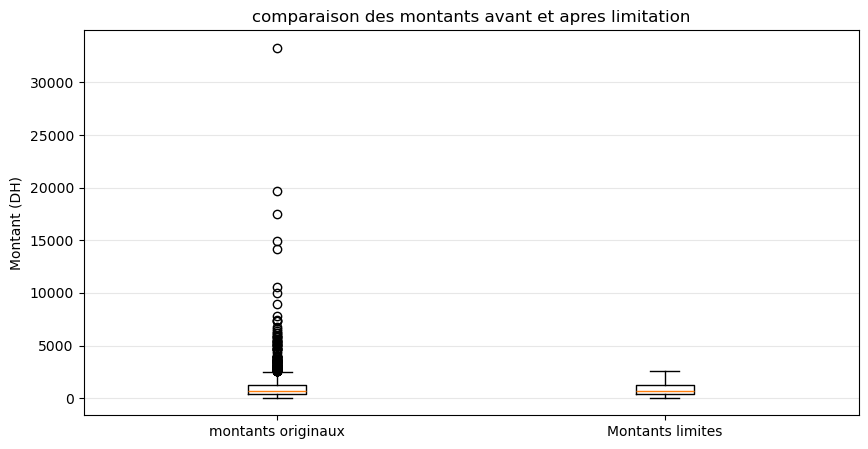

In [133]:

montants_originaux = X_ref['montant_dh']
montants_limites = montants_originaux.clip(
  lower=limite_inf,
    upper=limite_sup)
plt.figure(figsize=(10, 5))
plt.boxplot(
    [montants_originaux.dropna(), montants_limites.dropna()],
    tick_labels=['montants originaux', 'Montants limites'])
plt.title("comparaison des montants avant et apres limitation")
plt.ylabel("Montant (DH)")
plt.grid(axis='y', alpha=0.3)
plt.show()

## interpretation :
Nous avons comparé les montants originaux avec les montants limités à l'aide de deux boxplots. La limitation réduit l'influence des valeurs extrêmes sur la distribution des montants.

Ce choix doit être justifié, car les montants élevés ne sont pas nécessairement des erreurs. 
Les conserver permet de préserver les informations réelles, tandis que les limiter peut
améliorer certains modèles sensibles aux valeurs extrêmes. Il faut donc choisir le traitement selon la nature des données et l'objectif du modèle.

***18 : Application des méthodes de normalisation(MinMaxScaler,StandardScaler,RobustScaler)***

In [134]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
X_ref_montant = X_ref[['montant_dh']]
X_ver_montant = X_ver[['montant_dh']]
scalers = {
    'MinMaxScaler': MinMaxScaler(),
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler()}
resultats = {}
for nom, scaler in scalers.items():
    X_ref_transforme = scaler.fit_transform(X_ref_montant)
    X_ver_transforme = scaler.transform(X_ver_montant)
    resultats[nom] = {
        'Reference': X_ref_transforme.flatten(),
        'Verification': X_ver_transforme.flatten()}
print("---------groupe de preference ---------")
tableau_ref = pd.DataFrame({
    'MinMaxScaler': resultats['MinMaxScaler']['Reference'][:5],
    'StandardScaler': resultats['StandardScaler']['Reference'][:5],
    'RobustScaler': resultats['RobustScaler']['Reference'][:5]})
display(tableau_ref.round(3))
print("--------groupe deverification ---------")
tableau_ver = pd.DataFrame({
    'MinMaxScaler': resultats['MinMaxScaler']['Verification'][:5],
    'StandardScaler': resultats['StandardScaler']['Verification'][:5],
    'RobustScaler': resultats['RobustScaler']['Verification'][:5]})
display(tableau_ver.round(3))

---------groupe de preference ---------


,MinMaxScaler,StandardScaler,RobustScaler
0,0.012,-0.454,-0.340
1,0.015,-0.370,-0.207
2,0.013,-0.410,-0.272
3,0.075,1.099,2.109
4,0.011,-0.472,-0.369


--------groupe deverification ---------


,MinMaxScaler,StandardScaler,RobustScaler
0,0.023,-0.175,0.099
1,0.033,0.083,0.507
2,0.007,-0.572,-0.527
3,0.009,-0.507,-0.424
4,0.012,-0.430,-0.303


***19 : Comparaison des méthodes de normalisation face aux valeurs extrêmes***

In [142]:

montants = X_ref[['montant_dh']]
valeurs_choisies = [
    montants['montant_dh'].quantile(0.25),
    montants['montant_dh'].quantile(0.50),
    montants['montant_dh'].quantile(0.75),
    montants['montant_dh'].max()]
echantillon = pd.DataFrame({
    'montant_dh': valeurs_choisies
}, index=[
    'Montant habituel 1',
    'Montant habituel 2',
    'Montant habituel 3',
    'Montant très élevé'])
scalers = {
    'MinMaxScaler': MinMaxScaler(),
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler()}
for nom, scaler in scalers.items():
    scaler.fit(montants)
    valeurs_transformees = scaler.transform(
        echantillon[['montant_dh']])
    echantillon[nom] = valeurs_transformees.flatten()
echantillon.rename(
    columns={'montant_dh': 'Montant original (DH)'},
    inplace=True)
display(echantillon.round(3))

,Montant original (DH),MinMaxScaler,StandardScaler,RobustScaler
Montant habituel 1,393.095,0.011,-0.473,-0.371
Montant habituel 2,710.790,0.020,-0.238,0.000
Montant habituel 3,1249.878,0.037,0.161,0.629
Montant très élevé,33281.230,1.000,23.866,38.015


***20 : Comparaison des distributions après normalisation des données***

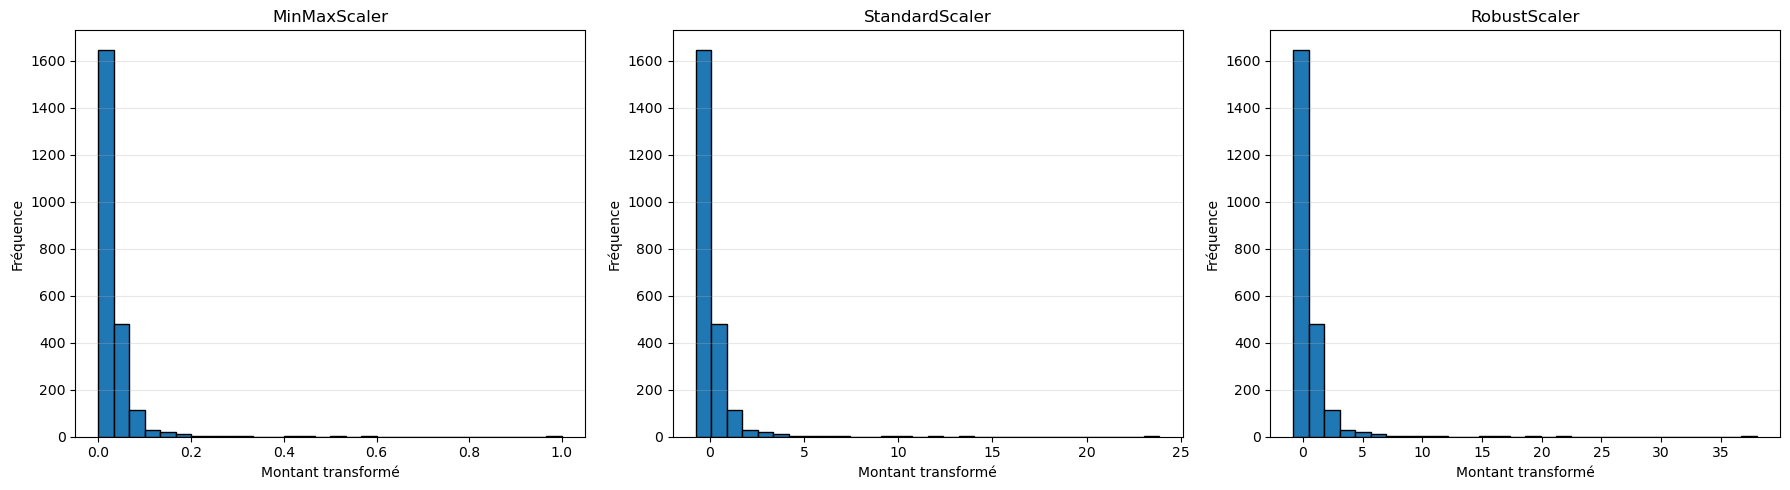

In [147]:

montants = X_ref[['montant_dh']]
scalers = {
    'MinMaxScaler': MinMaxScaler(),
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler()}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nom, scaler) in zip(axes, scalers.items()):
    valeurs = scaler.fit_transform(montants)
    ax.hist(valeurs.flatten(), bins=30, edgecolor='black')
    ax.set_title(nom)
    ax.set_xlabel('Montant transformé')
    ax.set_ylabel('Fréquence')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### interpretation:
Les trois méthodes conservent une distribution asymétrique à droite, mais modifient l'échelle des valeurs. MinMaxScaler et StandardScaler sont sensibles aux valeurs extrêmes, tandis que RobustScaler est moins sensible grâce à l'utilisation de la médiane et de l'IQR.

***21 : Dépassement de 1 avec MinMaxScaler***

In [155]:

X_ref_exemple = np.array([[10], [20], [30], [40], [50]])
nouvelle_transaction = np.array([[70]])
scaler = MinMaxScaler()
scaler.fit(X_ref_exemple)
resultat = scaler.transform(nouvelle_transaction)
print("nouvelle valeur transforme  :", resultat[0][0])

nouvelle valeur transforme  : 1.5


#### interpretation:
Oui, la valeur transformée peut dépasser 1. MinMaxScaler utilise le minimum et le maximum du groupe de référence. Ainsi, lorsqu'une nouvelle transaction dépasse le maximum de référence, sa valeur normalisée peut être supérieure à 1. Dans notre exemple, la valeur transformée est égale à 1,5.

***Partie 4 — Préparer des classes déséquilibrées***

***22 : Répartition des classes dans le groupe de référence***

In [156]:

effectifs = y_ref.value_counts().sort_index()
print("Nombre de transactions normales (0) :", effectifs[0])
print("Nombre de transactions frauduleuses (1) :", effectifs[1])
rapport = effectifs[0] / effectifs[1]
print("Rapport entre les deux classes :", round(rapport, 2))

Nombre de transactions normales (0) : 2194
Nombre de transactions frauduleuses (1) : 206
Rapport entre les deux classes : 10.65


#### interpretation:
Le rapport entre les deux classes est de 10,65. Cela signifie que les transactions normales (fraude = 0) sont environ 10,65 fois plus nombreuses que les transactions frauduleuses (fraude = 1). On constate donc un déséquilibre important entre les deux classes.

***23 : Application de RandomOverSampler***

In [159]:
from imblearn.over_sampling import RandomOverSampler
print("Avant RandomOverSampler :")
print(y_ref.value_counts().sort_index())
ros = RandomOverSampler(random_state=42)
X_ref_over, y_ref_over = ros.fit_resample(X_ref_final, y_ref)
print("\nAprès RandomOverSampler :")
print(pd.Series(y_ref_over).value_counts().sort_index())
print("\nDimensions avant :", X_ref_final.shape)
print("Dimensions après :", X_ref_over.shape)

Avant RandomOverSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64

Dimensions avant : (2400, 18)
Dimensions après : (4388, 18)


#### interpretation:

Avant l'application de RandomOverSampler, le groupe de référence contient 2 194 transactions normales (classe 0) et 206 transactions frauduleuses (classe 1), ce qui montre un déséquilibre important entre les deux classes.

Après le rééchantillonnage, chaque classe contient 2 194 lignes, pour un total de 4 388 lignes. RandomOverSampler a donc ajouté 1 988 lignes à la classe minoritaire afin d'équilibrer les deux classes.

Les nouvelles lignes sont des copies de transactions frauduleuses déjà existantes, sélectionnées aléatoirement avec remise. Elles ne représentent pas de nouvelles transactions réellement observées.

***24 : Application de RandomUnderSampler***

In [160]:
from imblearn.under_sampling import RandomUnderSampler
print("Avant RandomUnderSampler :")
print(y_ref.value_counts().sort_index())
rus = RandomUnderSampler(random_state=42)
X_ref_under, y_ref_under = rus.fit_resample(X_ref_final, y_ref)
print("\nAprès RandomUnderSampler :")
print(pd.Series(y_ref_under).value_counts().sort_index())
print("\nNombre de lignes avant :", len(y_ref))
print("Nombre de lignes conservées :", len(y_ref_under))
print("Nombre de lignes supprimées :", len(y_ref) - len(y_ref_under))

Avant RandomUnderSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes conservées : 412
Nombre de lignes supprimées : 1988


#### interpretation:

Avant l'application de RandomUnderSampler, le groupe de référence contient 2 194 transactions normales (classe 0) et 206 transactions frauduleuses (classe 1), soit un total de 2 400 lignes.

Après le rééchantillonnage, chaque classe contient 206 lignes, pour un total de 412 lignes conservées. Ainsi, 1 988 lignes de la classe majoritaire ont été supprimées afin d'équilibrer les deux classes.

Le principal risque de cette méthode est la perte d'informations. En supprimant aléatoirement des transactions normales, certaines données importantes peuvent être perdues. Cela peut réduire la diversité des données utilisées pour entraîner le modèle et diminuer sa capacité à reconnaître correctement les transactions normales.

***25 : Illustration de SMOTE***

In [161]:

A = np.array([10, 20])
B = np.array([20, 40])
lambda_ = 0.5
synthetique = A + lambda_ * (B - A)
print("Observation réelle A :", A)
print("Observation réelle B :", B)
print("Observation synthétique :", synthetique)

Observation réelle A : [10 20]
Observation réelle B : [20 40]
Observation synthétique : [15. 30.]


#### interpretation
Dans cet exemple, deux observations réelles de la classe minoritaire sont utilisées : A = (10, 20) et B = (20, 40). En appliquant la méthode SMOTE avec un coefficient de 0,5, une nouvelle observation synthétique (15, 30) est obtenue.

Contrairement à RandomOverSampler, qui crée des copies d'observations existantes, SMOTE génère de nouvelles valeurs en interpolant entre deux observations de la classe minoritaire. La nouvelle observation se situe entre les deux points d'origine et ne correspond donc pas à une simple duplication.

Différence essentielle :
- RandomOverSampler : duplique des observations existantes.
- SMOTE : crée de nouvelles observations synthétiques par interpolation entre des observations minoritaires.

***26 : SMOTE et les variables catégorielles encodées en One-Hot***

Il faut faire attention lors de l'application de SMOTE aux variables catégorielles encodées en One-Hot Encoding, car l'interpolation peut produire des valeurs intermédiaires (par exemple 0,5) au lieu des valeurs binaires 0 et 1. Ces valeurs ne représentent pas des catégories valides.

Pour les données contenant à la fois des variables numériques et catégorielles, on peut utiliser **SMOTENC**, une méthode adaptée à ce type de données.

In [162]:

A = np.array([1, 0])
B = np.array([0, 1])
lambda_ = 0.5
synthetique = A + lambda_ * (B - A)
print("Observation A :", A)
print("Observation B :", B)
print("Observation synthétique :", synthetique)

Observation A : [1 0]
Observation B : [0 1]
Observation synthétique : [0.5 0.5]


***27 : Comparaison des effectifs avant et après rééquilibrage***

In [163]:

avant = y_ref.value_counts().sort_index()
apres_over = pd.Series(y_ref_over).value_counts().sort_index()
apres_under = pd.Series(y_ref_under).value_counts().sort_index()
tableau = pd.DataFrame({
    'Avant rééquilibrage': avant,
    'Après RandomOverSampler': apres_over,
    'Après RandomUnderSampler': apres_under})
tableau.index.name = 'Classe de fraude'
display(tableau)

,Avant rééquilibrage,Après RandomOverSampler,Après RandomUnderSampler
Classe de fraude,,,
0,2194,2194,206
1,206,2194,206


#### interpretation 
Avant le rééquilibrage, le groupe de référence contient 2 194 transactions normales et 206 transactions frauduleuses, ce qui montre un déséquilibre entre les deux classes.

Après l'application de RandomOverSampler, les deux classes contiennent chacune 2 194 observations, pour un total de 4 388 lignes. En revanche, après RandomUnderSampler, chaque classe contient 206 observations, pour un total de 412 lignes.

Le groupe de vérification ne doit pas être modifié, car il doit conserver sa distribution initiale afin d'évaluer le modèle dans des conditions proches de la réalité. Le rééquilibrage doit donc être effectué uniquement sur le groupe de référence.

### Partie 5 — Vérifier et enregistrer les données préparées

***28 : Création du ColumnTransformer final***

In [164]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
num_cols = X_ref.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_ref.select_dtypes(include=['object', 'category']).columns
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())])
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor_final = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)])
X_ref_final = preprocessor_final.fit_transform(X_ref)
X_ver_final = preprocessor_final.transform(X_ver)
print("Dimensions du groupe de référence :", X_ref_final.shape)
print("Dimensions du groupe de vérification :", X_ver_final.shape)

Dimensions du groupe de référence : (2400, 18)
Dimensions du groupe de vérification : (600, 18)


#### interpretation
Le préprocesseur final `ColumnTransformer` permet d'appliquer un traitement adapté à chaque type de variable.

Pour les variables numériques, les valeurs manquantes sont remplacées par la médiane, puis les données sont transformées avec `RobustScaler`, qui utilise la médiane et l'écart interquartile. Cette méthode est moins sensible aux valeurs extrêmes.

Pour les variables catégorielles, les valeurs manquantes sont remplacées par la modalité la plus fréquente, puis transformées en colonnes binaires à l'aide de `OneHotEncoder`.

Enfin, les deux traitements sont regroupés dans un seul préprocesseur. Celui-ci est ajusté uniquement sur le groupe de référence, puis appliqué au groupe de vérification. Cette séparation permet d'éviter la fuite de données (*Data Leakage*) et garantit que les deux groupes subissent le même prétraitement.

***29 : Ajustement et application du transformateur final***

In [168]:
import numpy as np
preprocessor_final.fit(X_ref)
X_ref_final = preprocessor_final.transform(X_ref)
X_ver_final = preprocessor_final.transform(X_ver)
print("Nombre de colonnes du groupe de référence :", X_ref_final.shape[1])
print("Nombre de colonnes du groupe de vérification :", X_ver_final.shape[1])
print("\nValeurs manquantes dans le groupe de référence :",
      np.isnan(X_ref_final).sum())
print("Valeurs manquantes dans le groupe de vérification :",
      np.isnan(X_ver_final).sum())
print("\nDimensions du groupe de référence :", X_ref_final.shape)
print("Dimensions du groupe de vérification :", X_ver_final.shape)

Nombre de colonnes du groupe de référence : 18
Nombre de colonnes du groupe de vérification : 18

Valeurs manquantes dans le groupe de référence : 0
Valeurs manquantes dans le groupe de vérification : 0

Dimensions du groupe de référence : (2400, 18)
Dimensions du groupe de vérification : (600, 18)


#### interpretation 
Le transformateur final a été ajusté uniquement sur le groupe de référence à l'aide de la méthode `fit()`. Ensuite, le même transformateur a été appliqué aux deux groupes avec la méthode `transform()`.

Les résultats montrent que les deux groupes possèdent le même nombre de colonnes, soit 18 colonnes. De plus, aucune valeur manquante n'est présente après le prétraitement.

Cette démarche garantit que les deux groupes utilisent les mêmes paramètres de transformation et permet d'éviter la fuite de données (*Data Leakage*), puisque les informations du groupe de vérification ne sont pas utilisées pendant l'ajustement du transformateur.

***30 : Gestion d'une nouvelle catégorie inconnue***

In [170]:

nouvelle_ligne = X_ver.iloc[[0]].copy()
nouvelle_ligne.loc[:, 'canal'] = 'canal_inconnu'
nouvelle_ligne_transformee = preprocessor_final.transform(nouvelle_ligne)
print("nouvelle catégorie :", nouvelle_ligne['canal'].values[0])
print("transformation effectuée sans erreur.")
print("dimensions après transformation :",
      nouvelle_ligne_transformee.shape)
print(nouvelle_ligne_transformee.toarray()
      if hasattr(nouvelle_ligne_transformee, "toarray")
      else nouvelle_ligne_transformee)

nouvelle catégorie : canal_inconnu
transformation effectuée sans erreur.
dimensions après transformation : (1, 18)
[[ 0.10375406 -0.29761905 -1.          0.30769231  0.          0.
   0.          0.          0.          1.          0.          0.
   0.          1.          0.          0.          0.          1.        ]]


#### interpretation 
Une nouvelle transaction contenant une catégorie de canal inconnue (`canal_inconnu`) a été créée afin de tester le fonctionnement de OneHotEncoder.

La transformation s'est effectuée sans erreur grâce au paramètre `handle_unknown='ignore'`. Ce paramètre permet à l'encodeur de gérer les catégories qui n'ont pas été rencontrées pendant la phase d'apprentissage. Dans ce cas, toutes les colonnes One-Hot associées à la variable concernée prennent la valeur 0.

Cette option permet donc d'appliquer le même préprocesseur à de nouvelles données, même lorsqu'elles contiennent des catégories inconnues.

***31 : Enregistrement et rechargement du transformateur avec Joblib***

In [172]:
import joblib
joblib.dump(preprocessor_final, 'preprocessor_final.pkl')
print("transformateur enregistré avec succès.")
preprocessor_charge = joblib.load('preprocessor_final.pkl')
print("transformateur rechargé avec succès.")
echantillon = X_ver.iloc[:5]
resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)
difference = np.abs(resultat_original - resultat_charge).max()
print("\ndifference maximale :", difference)
if np.allclose(resultat_original, resultat_charge):
    print("les deux transformateurs produisent les mêmes résultats.")
else:
    print("les résultats sont différents.")

transformateur enregistré avec succès.
transformateur rechargé avec succès.

difference maximale : 0.0
les deux transformateurs produisent les mêmes résultats.


#### Interprétation
Le transformateur final a été enregistré dans un fichier nommé `preprocessor_final.pkl` à l'aide de la bibliothèque Joblib, puis rechargé avec succès.

Une comparaison a été effectuée sur un échantillon de cinq observations du groupe de vérification. Les résultats obtenus avec le transformateur initial et le transformateur rechargé sont identiques.

Cela confirme que Joblib permet de sauvegarder et de réutiliser un transformateur déjà préparé, sans recalculer les médianes, les échelles ou les catégories apprises pendant la phase d'ajustement.

***32 : Bilan du travail réalisé***

Au cours de ce TP, plusieurs étapes de prétraitement ont été réalisées afin de préparer les données pour l'apprentissage automatique.

Tout d'abord, les doublons ont été identifiés et supprimés afin d'éviter la répétition des mêmes observations. Les valeurs manquantes ont été traitées par imputation : la médiane a été utilisée pour les variables numériques et la modalité la plus fréquente pour les variables catégorielles.

Ensuite, l'analyse des valeurs extrêmes de la variable `montant_dh` a permis de détecter 146 observations dépassant les limites définies par la méthode de l'écart interquartile (IQR). Les limites obtenues sont -892,08 DH et 2 535,05 DH. Ces valeurs n'ont pas nécessairement été supprimées, car elles peuvent correspondre à des transactions réellement exceptionnelles.

Pour la transformation des données, nous avons choisi `RobustScaler` pour les variables numériques, car il utilise la médiane et l'écart interquartile et est donc moins sensible aux valeurs extrêmes. Pour les variables catégorielles, nous avons utilisé `OneHotEncoder(handle_unknown='ignore')`, qui permet de convertir les catégories en variables binaires et de gérer les catégories inconnues.

Le déséquilibre des classes a également été étudié. Initialement, le groupe de référence contenait 2 194 transactions normales et 206 transactions frauduleuses. Avec `RandomOverSampler`, les deux classes ont atteint 2 194 observations chacune, soit 4 388 lignes au total. En revanche, avec `RandomUnderSampler`, chaque classe contenait 206 observations, soit 412 lignes au total. Le suréchantillonnage permet de conserver les observations majoritaires, tandis que le sous-échantillonnage entraîne une perte d'informations.

Enfin, le groupe de vérification a été conservé sans rééquilibrage afin de garantir une évaluation fiable du modèle. Le transformateur final a été enregistré avec Joblib pour pouvoir être réutilisé sans recalculer ses paramètres.

En conclusion, ces différentes opérations ont permis de préparer les données, de traiter les valeurs manquantes, de limiter l'influence des valeurs extrêmes et de réduire le déséquilibre entre les classes, tout en évitant la fuite de données.

#### Travail complémentaire (facultatif)

**A : Comparaison entre l imputation par la moyenne et par la médian**

In [176]:
from sklearn.impute import SimpleImputer
montants = X_ref[['montant_dh']]
imputer_mean = SimpleImputer(strategy='mean')
imputer_median = SimpleImputer(strategy='median')
imputer_mean.fit(montants)
imputer_median.fit(montants)
valeur_moyenne = imputer_mean.statistics_[0]
valeur_mediane = imputer_median.statistics_[0]
print("Moyenne :", valeur_moyenne)
print("Médiane :", valeur_mediane)

Moyenne : 1032.467776816609
Médiane : 710.79


#### interpretation 
La moyenne des montants est de 1 032,47 DH, tandis que la médiane est de 710,79 DH. Cette différence montre que les montants très élevés influencent la moyenne en augmentant sa valeur. La médiane est moins sensible aux valeurs extrêmes, car elle représente la valeur centrale des observations. Ainsi, pour notre jeu de données, l'imputation par la médiane est plus adaptée que l'imputation par la moyenne, car elle permet de limiter l'influence des transactions exceptionnellement élevées.

***B : Rééquilibrage avec SMOTENC***

In [178]:

from imblearn.over_sampling import SMOTENC
X_exemple = pd.DataFrame({
    'montant_dh': [
        100, 150, 200, 250, 300, 350,
        400, 450, 500, 550, 600, 650,
        2000, 2200, 2400, 2600, 2800, 3000
    ],
    'anciennete_mois': [
        12, 15, 18, 20, 24, 30,
        32, 35, 40, 42, 45, 48,
        2, 3, 4, 5, 6, 8
    ],
    'canal': [
        'agence', 'application', 'site_web',
        'agence', 'application', 'site_web',
        'agence', 'application', 'site_web',
        'agence', 'application', 'site_web',
        'application', 'site_web', 'application',
        'site_web', 'application', 'site_web'],
    'region': [
        'Casablanca', 'Marrakech', 'Rabat',
        'Casablanca', 'Marrakech', 'Rabat',
        'Casablanca', 'Marrakech', 'Rabat',
        'Casablanca', 'Marrakech', 'Rabat',
        'Marrakech', 'Rabat', 'Casablanca',
        'Marrakech', 'Rabat', 'Casablanca']})
y_exemple = pd.Series(
    [0] * 12 + [1] * 6,
    name='fraude')
print("distribution avant SMOTENC :")
print(y_exemple.value_counts().sort_index())

Distribution avant SMOTENC :
fraude
0    12
1     6
Name: count, dtype: int64


**Appliquer SMOTENC**

In [179]:
smotenc = SMOTENC(
    categorical_features=[2, 3],
    random_state=42
)

X_smotenc, y_smotenc = smotenc.fit_resample(
    X_exemple,
    y_exemple
)

print("Distribution après SMOTENC :")
print(y_smotenc.value_counts().sort_index())

print("\nDimensions avant :", X_exemple.shape)
print("Dimensions après :", X_smotenc.shape)

Distribution après SMOTENC :
fraude
0    12
1    12
Name: count, dtype: int64

Dimensions avant : (18, 4)
Dimensions après : (24, 4)


In [180]:
print("Catégories de canal :")
print(X_smotenc['canal'].unique())

print("\nCatégories de région :")
print(X_smotenc['region'].unique())

print("\nQuelques observations générées :")
display(X_smotenc.tail(6))

Catégories de canal :
['agence' 'application' 'site_web']

Catégories de région :
['Casablanca' 'Marrakech' 'Rabat']

Quelques observations générées :


,montant_dh,anciennete_mois,canal,region
18,2319,3,application,Casablanca
19,2506,4,application,Rabat
20,2875,7,application,Rabat
21,2434,4,site_web,Rabat
22,2226,3,site_web,Marrakech
23,2440,4,application,Marrakech


#### interpretation 
Dans cet exemple, nous avons utilisé SMOTENC pour rééquilibrer un jeu de données contenant des variables numériques (`montant_dh` et `anciennete_mois`) et des variables catégorielles (`canal` et `region`).

Avant le rééquilibrage, le jeu de données contient 12 transactions normales et 6 transactions frauduleuses. Après l'application de SMOTENC, les deux classes contiennent chacune 12 observations.

L'examen des catégories générées permet de vérifier que les variables catégorielles conservent des valeurs valides, contrairement à une interpolation classique de SMOTE appliquée directement à des données encodées en One-Hot Encoding.

**Points à prendre en compte :**
- Il faut identifier correctement les variables catégorielles avant d'appliquer SMOTENC.
- Il faut conserver les variables catégorielles sous forme de catégories, sans les transformer préalablement en One-Hot Encoding.
- Le rééquilibrage doit être effectué uniquement sur le groupe de référence (entraînement), et non sur le groupe de vérification.
- Il faut vérifier que les catégories générées restent cohérentes avec les catégories présentes dans les données initiales.

## Merci pour votre attention et votre encadrement